### **SELECTED CANDIDATES**
- Recent Popularity
- Popularity (baseline)

Metrics: HIT@12 - Precision@12
* Test user: No purchases before the anchor, at least one in the test window
* Hit: Any article bought in the window
* Items: no history

Expected phenomenon:
* The test group may be small on a 10% sample, so expect wide CIs and say so.
* Don’t judge it with personalised metrics, since every user gets the same list.
* Check that the popularity window doesn’t include test days.

In [1]:
from utils.load_splits import load_splits
from utils.eval_tools import compare_models, bootstrap_compare, plot_comparison, plot_bootstrap
import pandas as pd
import numpy as np

#models
from models.popularity import PopularityModel

In [4]:
# data
train_val_raw, test_raw=load_splits(
    train_path="../data/split/train.parquet",
    val_path="../data/split/val.parquet",
    test_path="../data/split/test.parquet",
    concat_train_val=True
)

train_val = train_val_raw[train_val_raw['sales_channel_id']==2]
test = test_raw[test_raw['sales_channel_id']==2]
assert train_val.t_dat.max() < test.t_dat.min()

In [5]:
# models
models={
    "popularity": PopularityModel(),
    "pop_7day": PopularityModel(window_days=7)
}

In [6]:
summary, per_user=compare_models(models, history_df=train_val, target_df=test, baseline="popularity", problem="cold_start")

Setup: user_group=cold, truth_mode=all -> 876 users, 2,427 relevant purchases
        17.2% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating popularity ...
Evaluating pop_7day ...


In [7]:
ci_df, paired_df=bootstrap_compare(per_user, baseline="popularity", k=12)

In [8]:
# freeze .csv
summary.to_csv("frozen_results/test_summary.csv")
ci_df.to_csv("frozen_results/ci_df_test.csv")
paired_df.to_csv("frozen_results/paired_df_test.csv")

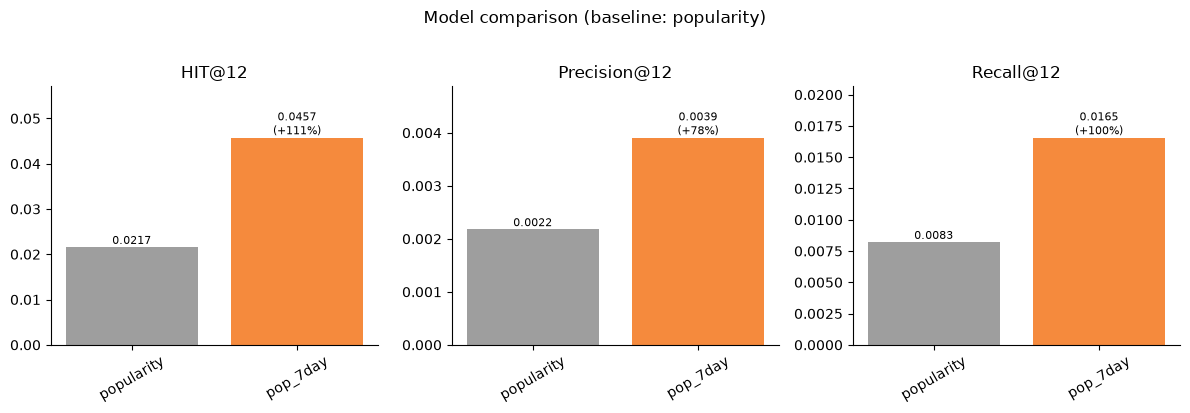

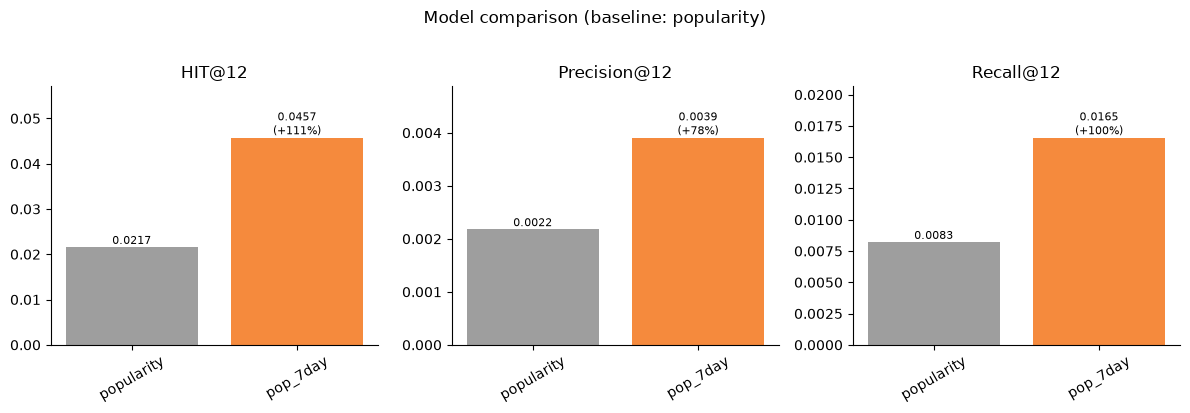

In [9]:
plot_comparison(summary, baseline="popularity", k=12, save_path="figures/coldstart/test_summary.png")

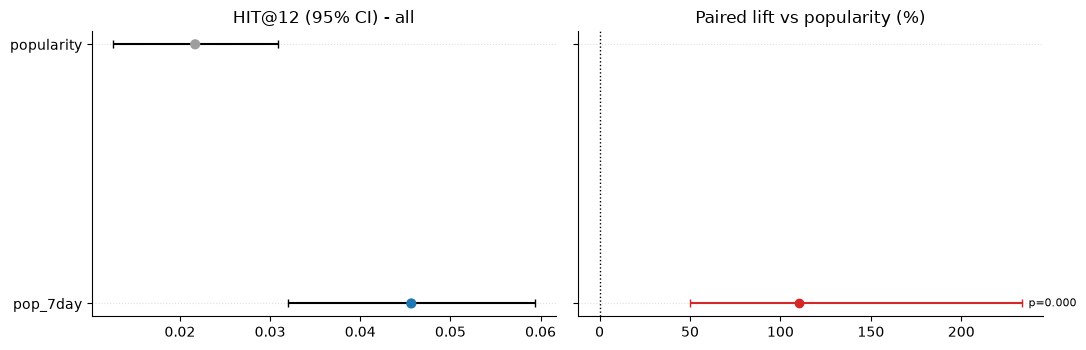

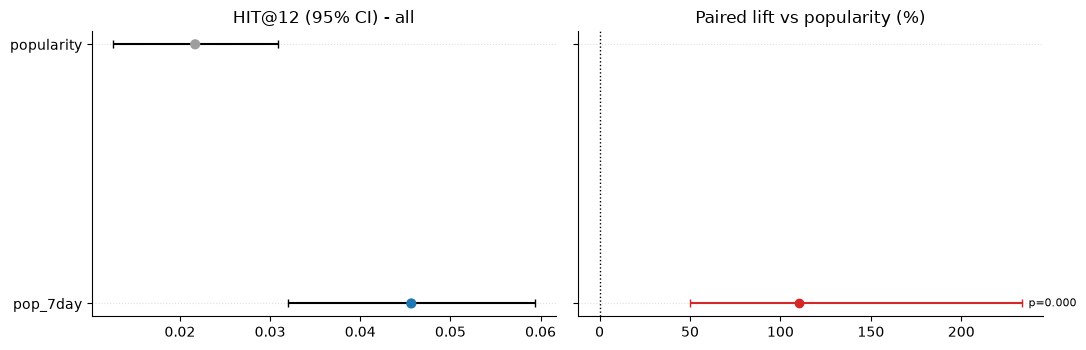

In [10]:
plot_bootstrap(ci_df, paired_df, baseline="popularity", save_path="figures/coldstart/test_bootstrap.png")

### **conclusion**

The `recent_popularity` with time window =7 is significantly better the pure `popularity`